#Amélioration de base d'image à l'aide d'opérations mathématiques

Nous allons examiner quelques-unes des opérations fondamentales souvent utilisées dans les pipelines de vision par ordinateur, souvent en amont des techniques de deep learning. Dans ce notebook, nous couvrirons :

* Opérations arithmétiques comme l'addition, la multiplication
* Seuillage et masquage
* Opérations logiques comme OR, AND, XOR

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from zipfile import ZipFile
from urllib.request import urlretrieve

from IPython.display import Image

%matplotlib inline

##  Téléchargement des images

In [ ]:
def download_and_unzip(url, save_path):
    print(f"Downloading and extracting assests....", end="")

    # Downloading zip file using urllib package.
    urlretrieve(url, save_path)

    try:
        # Extracting zip file using the zipfile package.
        with ZipFile(save_path) as z:
            # Extract ZIP file contents in the same directory.
            z.extractall(os.path.split(save_path)[0])

        print("Done")

    except Exception as e:
        print("\nInvalid file.", e)

In [ ]:
URL = r"https://www.dropbox.com/s/0oe92zziik5mwhf/opencv_bootcamp_assets_NB4.zip?dl=1"

asset_zip_path = os.path.join(os.getcwd(), "opencv_bootcamp_assets_NB4.zip")

# Download if assest ZIP does not exists.
if not os.path.exists(asset_zip_path):
    download_and_unzip(URL, asset_zip_path)

### Image d'origine

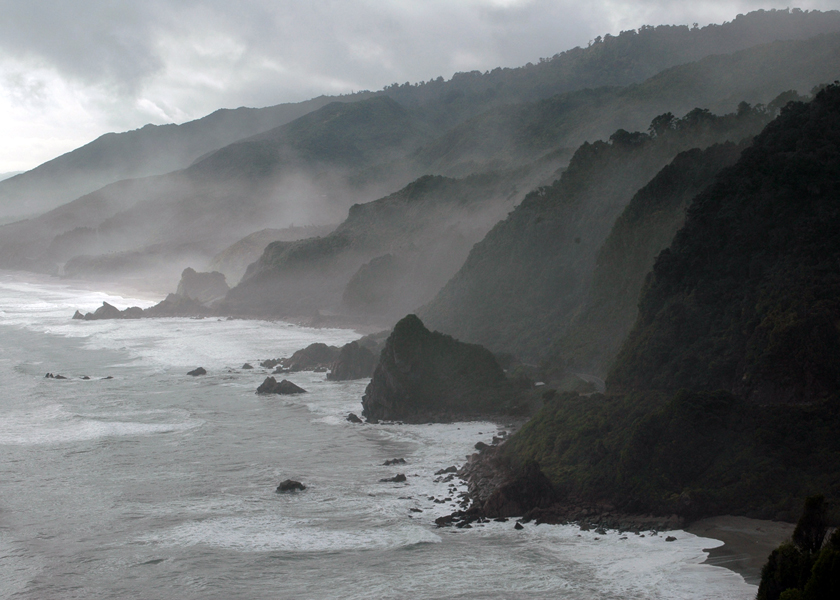

In [ ]:
img_bgr = cv2.imread("New_Zealand_Coast.jpg", cv2.IMREAD_COLOR)
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# Display 18x18 pixel image.
Image(filename="New_Zealand_Coast.jpg")

array([[[188, 183, 174],
        [189, 183, 176],
        [189, 181, 174],
        ...,
        [176, 170, 163],
        [177, 171, 164],
        [176, 172, 167]],

       [[189, 183, 176],
        [189, 183, 176],
        [190, 182, 175],
        ...,
        [177, 171, 166],
        [178, 172, 167],
        [173, 169, 164]],

       [[186, 180, 173],
        [188, 180, 173],
        [188, 181, 172],
        ...,
        [175, 171, 166],
        [175, 171, 166],
        [174, 170, 165]],

       ...,

       [[156, 157, 153],
        [154, 155, 151],
        [152, 150, 150],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[154, 153, 149],
        [154, 153, 149],
        [154, 152, 152],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]],

       [[155, 154, 150],
        [155, 153, 152],
        [155, 153, 152],
        ...,
        [  0,   0,   0],
        [  0,   0,   0],
        [  0,   0,   0]]], dtype=uint8)
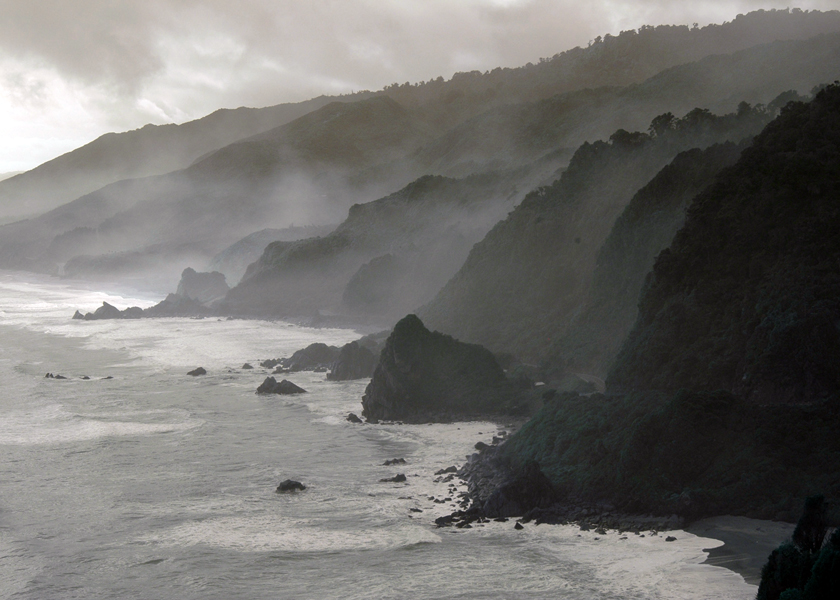

In [ ]:
img_bgr

## Addition et luminosité

La première opération que nous abordons est l’addition simple d’images. Cela entraîne une augmentation ou une diminution de la luminosité de l’image, puisque nous augmentons ou diminuons finalement les valeurs d’intensité de chaque pixel. Ainsi, cela se traduira par une augmentation/diminution globale de la luminosité.


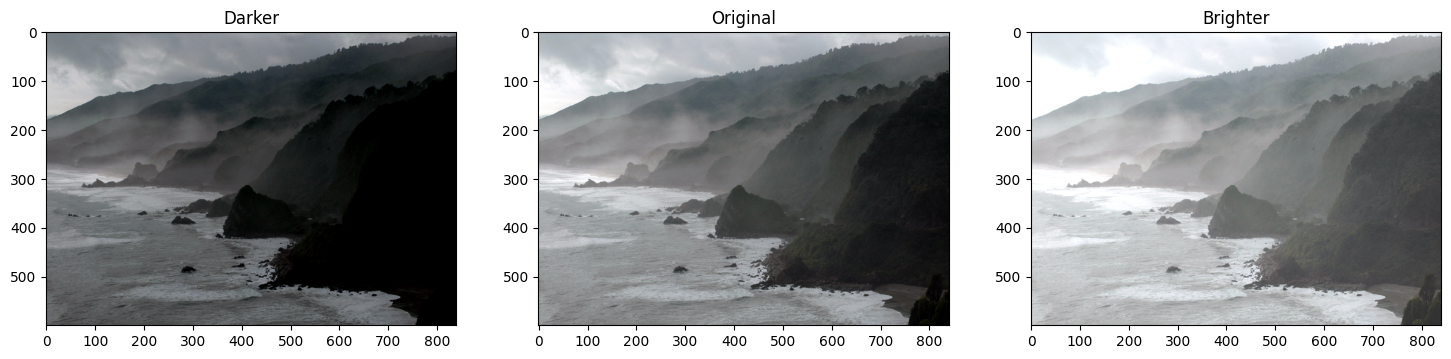

In [ ]:
matrix = np.ones(img_rgb.shape, dtype="uint8") * 50

img_rgb_brighter = cv2.add(img_rgb, matrix)
img_rgb_darker   = cv2.subtract(img_rgb, matrix)

# Show the images
plt.figure(figsize=[18, 5])
plt.subplot(131); plt.imshow(img_rgb_darker);  plt.title("Darker");
plt.subplot(132); plt.imshow(img_rgb);         plt.title("Original");
plt.subplot(133); plt.imshow(img_rgb_brighter);plt.title("Brighter");

In [ ]:
np.max(img_rgb_brighter)

np.uint8(254)

## Multiplication ou contraste
Tout comme l’addition peut entraîner un changement de luminosité, la multiplication peut être utilisée pour améliorer le contraste de l’image.

Le contraste est la différence dans les valeurs d’intensité des pixels d’une image. Multiplier les valeurs d’intensité par une constante peut rendre la différence plus grande ou plus petite (si le facteur de multiplication est < 1).

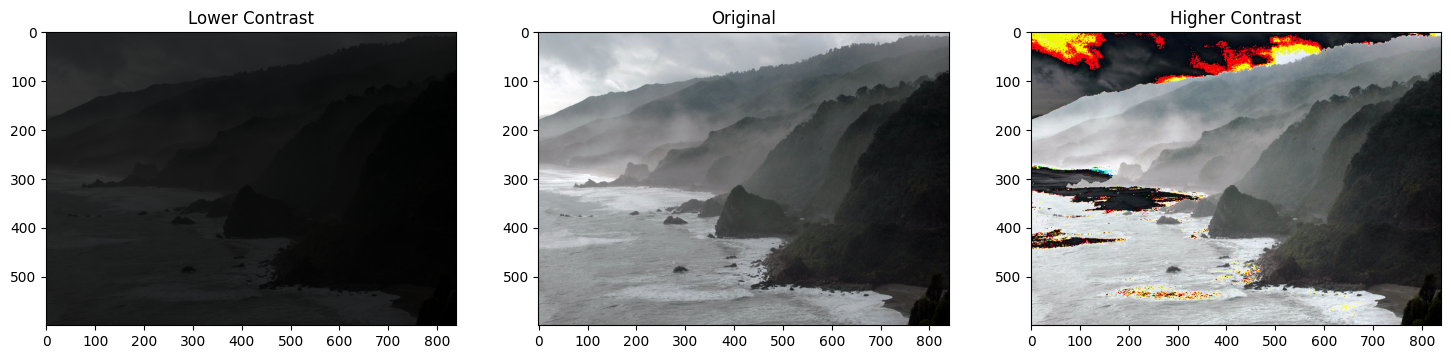

In [ ]:
matrix1 = np.ones(img_rgb.shape) * 0.2
matrix2 = np.ones(img_rgb.shape) * 1.4

img_rgb_darker   = np.uint8(cv2.multiply(np.float64(img_rgb), matrix1))
img_rgb_brighter = np.uint8(cv2.multiply(np.float64(img_rgb), matrix2))

# Show the images
plt.figure(figsize=[18,5])
plt.subplot(131); plt.imshow(img_rgb_darker);  plt.title("Lower Contrast");
plt.subplot(132); plt.imshow(img_rgb);         plt.title("Original");
plt.subplot(133); plt.imshow(img_rgb_brighter);plt.title("Higher Contrast");

### Que s'est-il passé ?

Pourquoi certains pixels ont des couleurs bizarres ?

### Gérer l'overflow avec np.clip

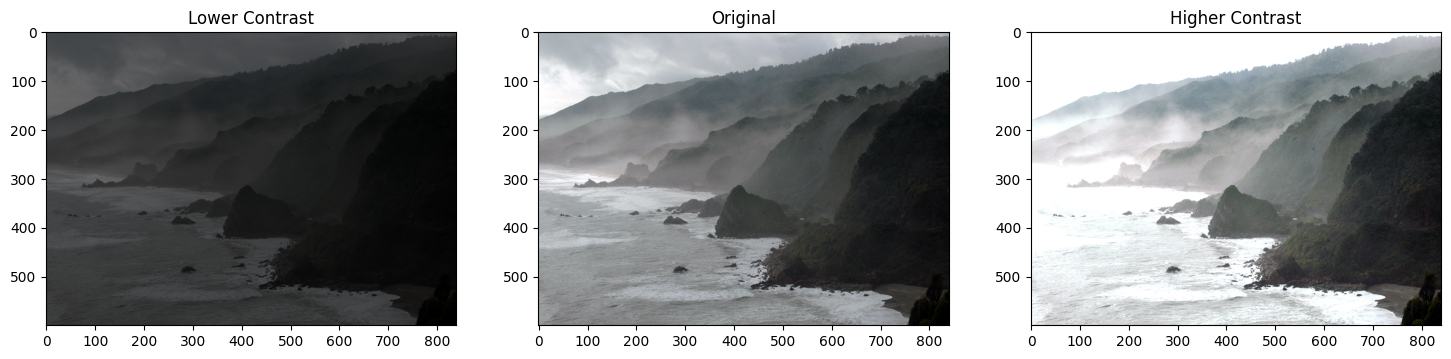

In [ ]:
matrix1 = np.ones(img_rgb.shape) * 0.4
matrix2 = np.ones(img_rgb.shape) * 1.6

img_rgb_lower  = np.uint8(cv2.multiply(np.float64(img_rgb), matrix1))
img_rgb_higher = np.uint8(np.clip(cv2.multiply(np.float64(img_rgb), matrix2), 0, 255))

# Show the images
plt.figure(figsize=[18,5])
plt.subplot(131); plt.imshow(img_rgb_lower); plt.title("Lower Contrast");
plt.subplot(132); plt.imshow(img_rgb);       plt.title("Original");
plt.subplot(133); plt.imshow(img_rgb_higher);plt.title("Higher Contrast");

In [ ]:
np.max(cv2.multiply(np.float64(img_rgb), matrix2))

408.0

In [ ]:
408%255

153

## Threshold sur des images
Les images binaires ont de nombreux cas d’utilisation en traitement d’images. L’un des cas d’utilisation les plus courants est la création de masques. Les masques d’image nous permettent de traiter des parties spécifiques d’une image tout en gardant les autres parties intactes.

Le seuillage d’image est utilisé pour créer des images binaires à partir d’images en niveaux de gris. Vous pouvez utiliser différents seuils pour créer différentes images binaires à partir de la même image d’origine.

### <font color="green">Syntaxe </font>

``` python
retval, dst = cv2.threshold( src, thresh, maxval, type[, dst] )
```

### <font style="color:rgb(8,133,37)">OpenCV Documentation</font>

<a href="https://docs.opencv.org/4.5.1/d7/d1b/group__imgproc__misc.html#gae8a4a146d1ca78c626a53577199e9c57
https://docs.opencv.org/4.5.1/d7/d4d/tutorial_py_thresholding.html" target="_blank">Documentation link</a>

(572, 800)


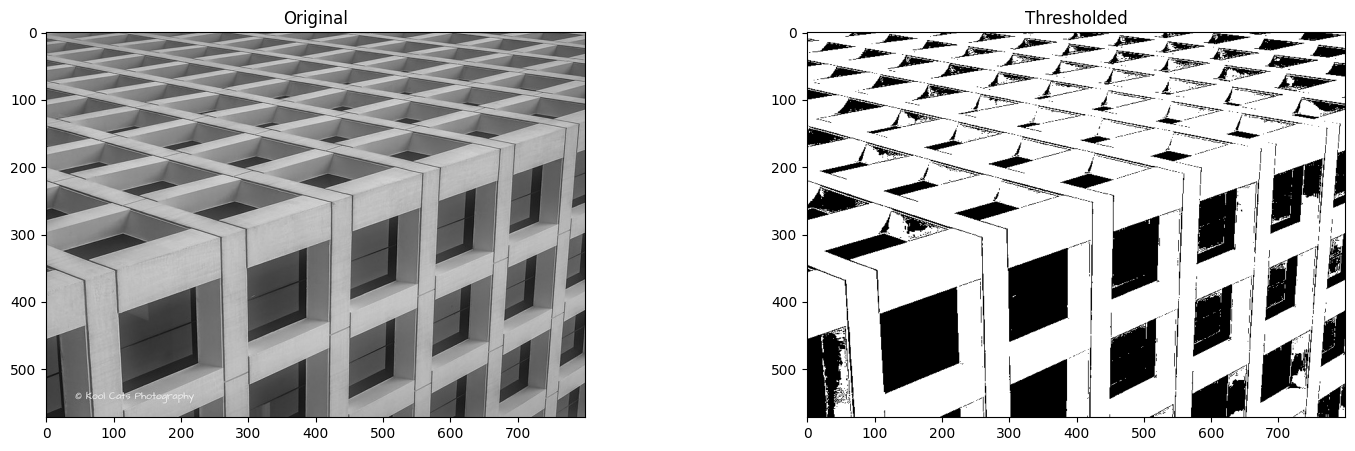

In [ ]:
img_read = cv2.imread("building-windows.jpg", cv2.IMREAD_GRAYSCALE)
retval, img_thresh = cv2.threshold(img_read, 100, 255, cv2.THRESH_BINARY)

# Show the images
plt.figure(figsize=[18, 5])

plt.subplot(121);plt.imshow(img_read, cmap="gray");  plt.title("Original")
plt.subplot(122);plt.imshow(img_thresh, cmap="gray");plt.title("Thresholded")

print(img_thresh.shape)

In [1]:
## Exercice

Recoder la fonction threshold avec Numpy : elle prend une valeur de seuil en entrée .

## Application : Lecteur de partitions

Supposons que vous vouliez créer une application capable de lire (décoder) des partitions musicales. C’est similaire à la
Reconnaissance Optique de Caractères (OCR) pour les documents textuels, où le but est de reconnaître les caractères du texte. Dans l’une ou l’autre application, l’une des premières étapes du pipeline de traitement consiste à isoler les informations importantes dans l’image d’un document (en les séparant de l’arrière-plan). Cette tâche peut être accomplie à l’aide de techniques de seuillage.
Jetons un œil à un exemple.

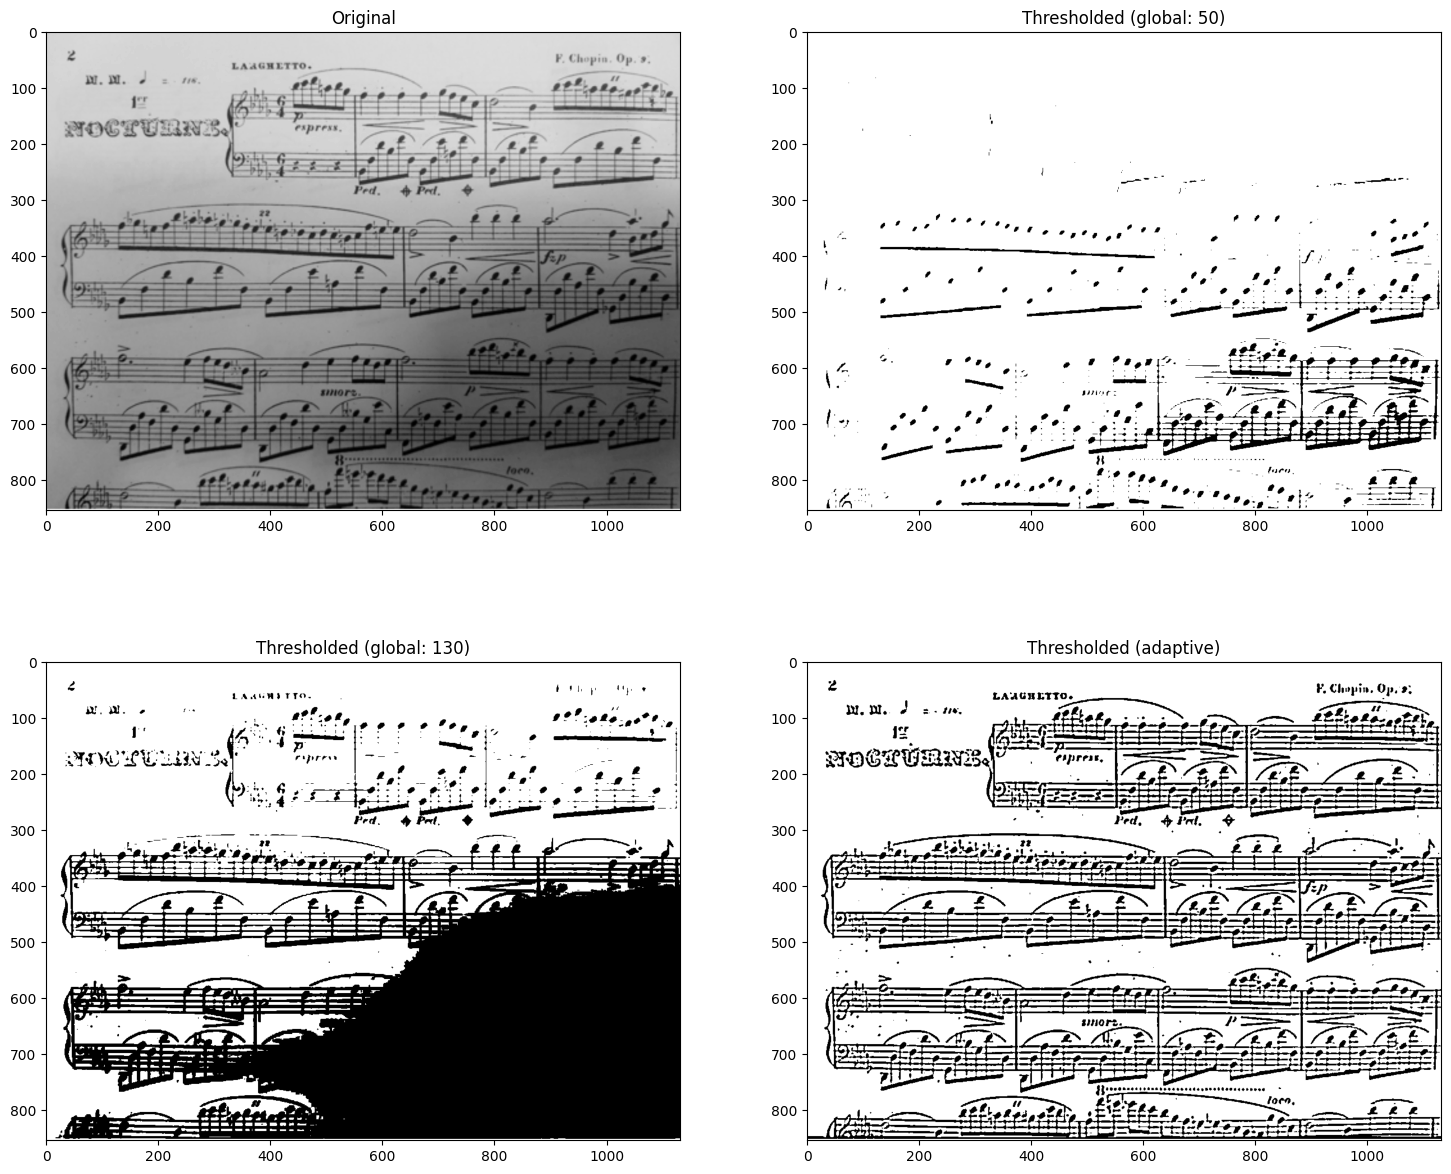

In [ ]:
# Read the original image
img_read = cv2.imread("Piano_Sheet_Music.png", cv2.IMREAD_GRAYSCALE)

# Perform global thresholding
retval, img_thresh_gbl_1 = cv2.threshold(img_read, 50, 255, cv2.THRESH_BINARY)

# Perform global thresholding
retval, img_thresh_gbl_2 = cv2.threshold(img_read, 130, 255, cv2.THRESH_BINARY)

# Perform adaptive thresholding
img_thresh_adp = cv2.adaptiveThreshold(img_read, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 11, 7)

# Show the images
plt.figure(figsize=[18,15])
plt.subplot(221); plt.imshow(img_read,        cmap="gray");  plt.title("Original");
plt.subplot(222); plt.imshow(img_thresh_gbl_1,cmap="gray");  plt.title("Thresholded (global: 50)");
plt.subplot(223); plt.imshow(img_thresh_gbl_2,cmap="gray");  plt.title("Thresholded (global: 130)");
plt.subplot(224); plt.imshow(img_thresh_adp,  cmap="gray");  plt.title("Thresholded (adaptive)");

## Operations binaires sur des images

### <font style="color:rgb(8,133,37)">Syntaxe</font>

`cv2.bitwise_and()`, `cv2.bitwise_or()`, `cv2.bitwise_xor()`, `cv2.bitwise_not()`

``` python
dst = cv2.bitwise_and( src1, src2[, dst[, mask]] )
```

### <font style="color:rgb(8,133,37)">OpenCV Documentation</font>

1. <a href="https://docs.opencv.org/4.5.1/d0/d86/tutorial_py_image_arithmetics.html" target="_blank">Arithmetic Operations on Images</a>

2. <a href="https://docs.opencv.org/4.5.0/d2/de8/group__core__array.html#ga60b4d04b251ba5eb1392c34425497e14" target="_blank">bitwise_and(...) function</a>

(200, 499)


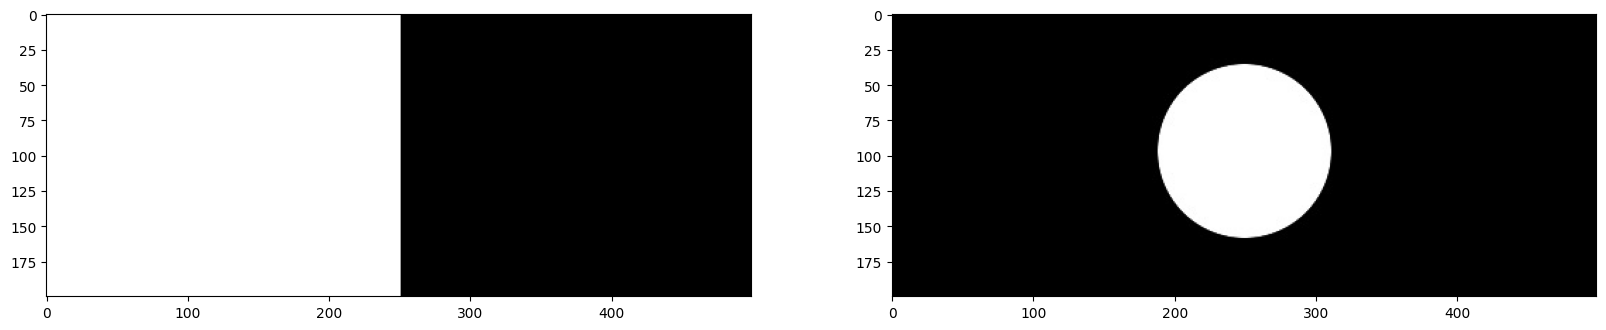

In [ ]:
img_rec = cv2.imread("rectangle.jpg", cv2.IMREAD_GRAYSCALE)

img_cir = cv2.imread("circle.jpg", cv2.IMREAD_GRAYSCALE)

plt.figure(figsize=[20, 5])
plt.subplot(121);plt.imshow(img_rec, cmap="gray")
plt.subplot(122);plt.imshow(img_cir, cmap="gray")
print(img_rec.shape)

### <font color="green">Opérateur AND </font>

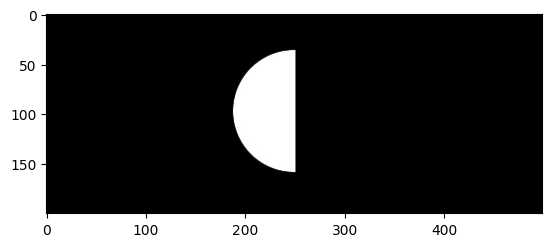

In [ ]:
result = cv2.bitwise_and(img_rec, img_cir, mask=None)
plt.imshow(result, cmap="gray")

### <font color="green">Opérateur OR </font>

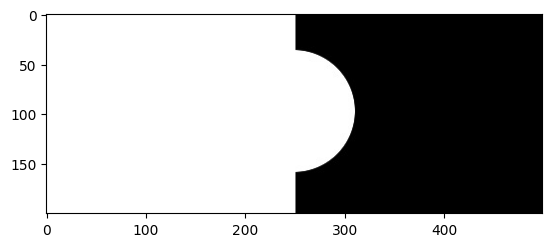

In [ ]:
result = cv2.bitwise_or(img_rec, img_cir, mask=None)
plt.imshow(result, cmap="gray")

### <font color="green">Opérateur XOR </font>

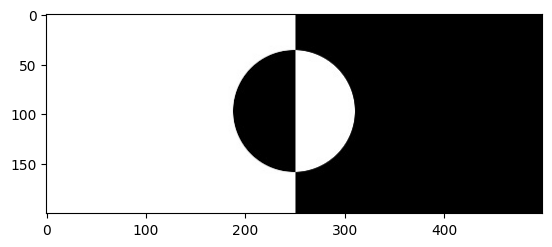

In [ ]:
result = cv2.bitwise_xor(img_rec, img_cir, mask=None)
plt.imshow(result, cmap="gray")

## Application: Manipulation de logo

Dans cette section, nous vous montrerons comment remplir les lettres blanches du logo Coca-Cola ci-dessous avec une image d’arrière-plan.

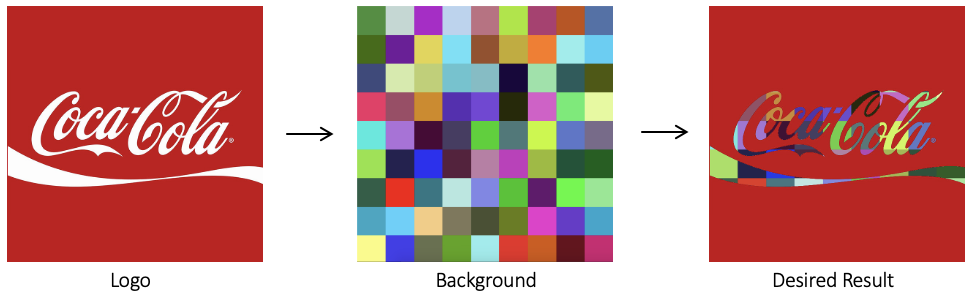

In [ ]:
Image(filename='Logo_Manipulation.png')

### <font color="green">Image de premier-plan</font>

(700, 700, 3)


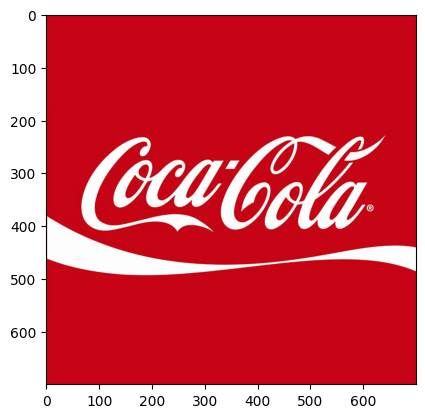

In [ ]:
img_bgr = cv2.imread("coca-cola-logo.png")
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)

print(img_rgb.shape)

In [ ]:
logo_w = img_rgb.shape[0]
logo_h = img_rgb.shape[1]

### <font color="green">Image de 2nd plan</font>

In [ ]:
# Read in image of color cheackerboad background
img_background_bgr = cv2.imread("checkerboard_color.png")
img_background_rgb = cv2.cvtColor(img_background_bgr, cv2.COLOR_BGR2RGB)
print(img_background_rgb.shape)

(1800, 1800, 3)


(700, 700, 3)


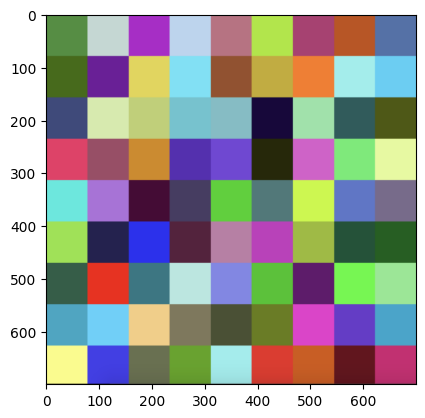

In [ ]:
# Set desired width (logo_w) and maintain image aspect ratio
aspect_ratio = logo_w / img_background_rgb.shape[1]
dim = (logo_w, int(img_background_rgb.shape[0] * aspect_ratio))

# Resize background image to sae size as logo image
img_background_rgb = cv2.resize(img_background_rgb, dim, interpolation=cv2.INTER_AREA)
img_background_rgb = cv2.resize(img_background_rgb, (700, 700), interpolation=cv2.INTER_AREA)

plt.imshow(img_background_rgb)
print(img_background_rgb.shape)

### <font color="green">Creation d'un masque pour l'image d'origine </font>

(700, 700)


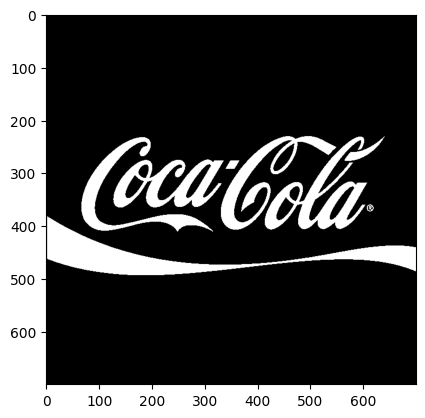

In [ ]:
img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

# Apply global thresholding to creat a binary mask of the logo
retval, img_mask = cv2.threshold(img_gray, 127, 255, cv2.THRESH_BINARY)

plt.imshow(img_mask, cmap="gray")
print(img_mask.shape)

### <font color="green">Inversion du masque </font>

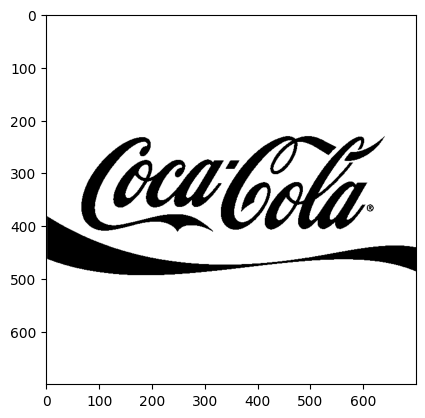

In [ ]:
# Create an inverse mask
img_mask_inv = cv2.bitwise_not(img_mask)
plt.imshow(img_mask_inv, cmap="gray")

### <font color="green">Appliquer l'image de background au masque</font>

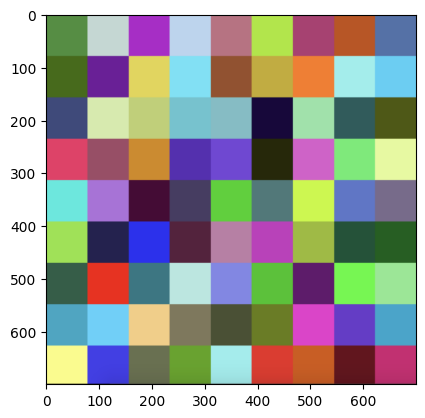

In [ ]:
plt.imshow(img_background_rgb)

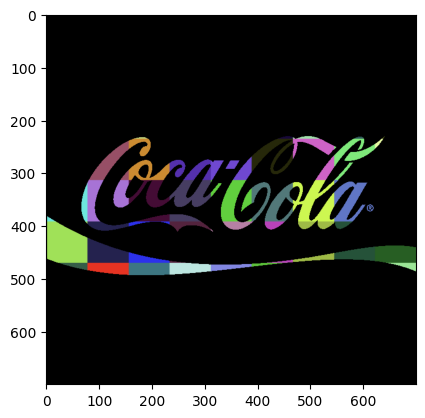

In [ ]:
# Create colorful background "behind" the logo lettering
img_background = cv2.bitwise_and(img_background_rgb, img_background_rgb, mask=img_mask)
plt.imshow(img_background)

### <font color="green">Isoler le premier plan de l'image</font>

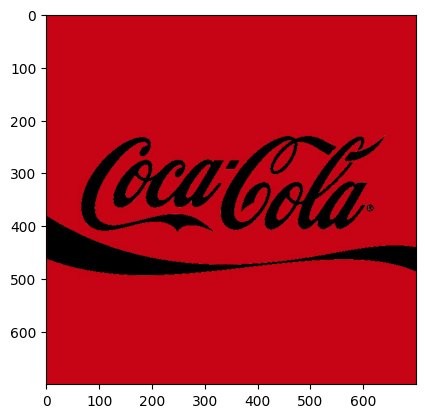

In [ ]:
# Isolate foreground (red from original image) using the inverse mask
img_foreground = cv2.bitwise_and(img_rgb, img_rgb, mask=img_mask_inv)
plt.imshow(img_foreground)

### <font color="green">Result: Merge le premier plan et le 2nd plan</font>

True

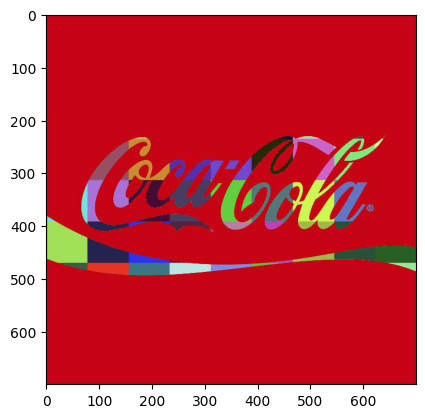

In [ ]:
# Add the two previous results obtain the final result
result = cv2.add(img_background, img_foreground)
plt.imshow(result)
cv2.imwrite("logo_final.png", result[:, :, ::-1])